# Train your first models, one step at a time

This notebook walks through the examples in this folder a step at a time, so you can see what each step produces before moving on. Everything runs on your own machine: no Google, no OpenAI, no cloud account, no API key.

**How to use it.** Click a cell and press **Shift + Enter** to run it and move to the next one. Run the cells in order, top to bottom. You can change any number and run the cell again to see what happens. The outputs you see right now were saved from an earlier run, so you can also just read through first.

| Part | What you do | Same code as |
|---|---|---|
| 1 | Fit a straight line by hand, in plain Python | `train_stdlib.py` |
| 2 | Train and compare three classifiers with scikit-learn | `train_sklearn.py`, `visualize.py` |
| 3 | Save the chosen model and load it back | `save_model.py`, `client.py` |

Every data science project follows the same four steps: **data → split → train → evaluate**. Watch for them in Part 1 and again in Part 2.

In [1]:
# Setup: how the charts should look. Run this once. Nothing in this cell is machine learning.
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = "retina"      # sharper charts on high-resolution screens

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"      # one colour per category, always in this order
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": INK2,
})
print("Charts are ready.")

Charts are ready.


---
# Part 1. Fit a straight line by hand

Eight students told us how many hours they studied and what they scored on the exam. We want a formula that predicts the score from the hours:

**score = weight × hours + bias**

Training means finding good values for `weight` and `bias`. This part uses plain Python so nothing is hidden.

## Step 1. The data, and the split

In [2]:
# (hours studied, exam score) for eight students.
data = [(1, 52), (2, 58), (3, 64), (4, 71), (5, 75), (6, 82), (7, 88), (8, 93)]

# Hold back the last two rows. The model never sees them during training,
# so they are a fair test of whether it learned the pattern.
train, test = data[:-2], data[-2:]

print("Training rows:", train)
print("Test rows:    ", test)

Training rows: [(1, 52), (2, 58), (3, 64), (4, 71), (5, 75), (6, 82)]
Test rows:     [(7, 88), (8, 93)]


Always look at the data before training anything.

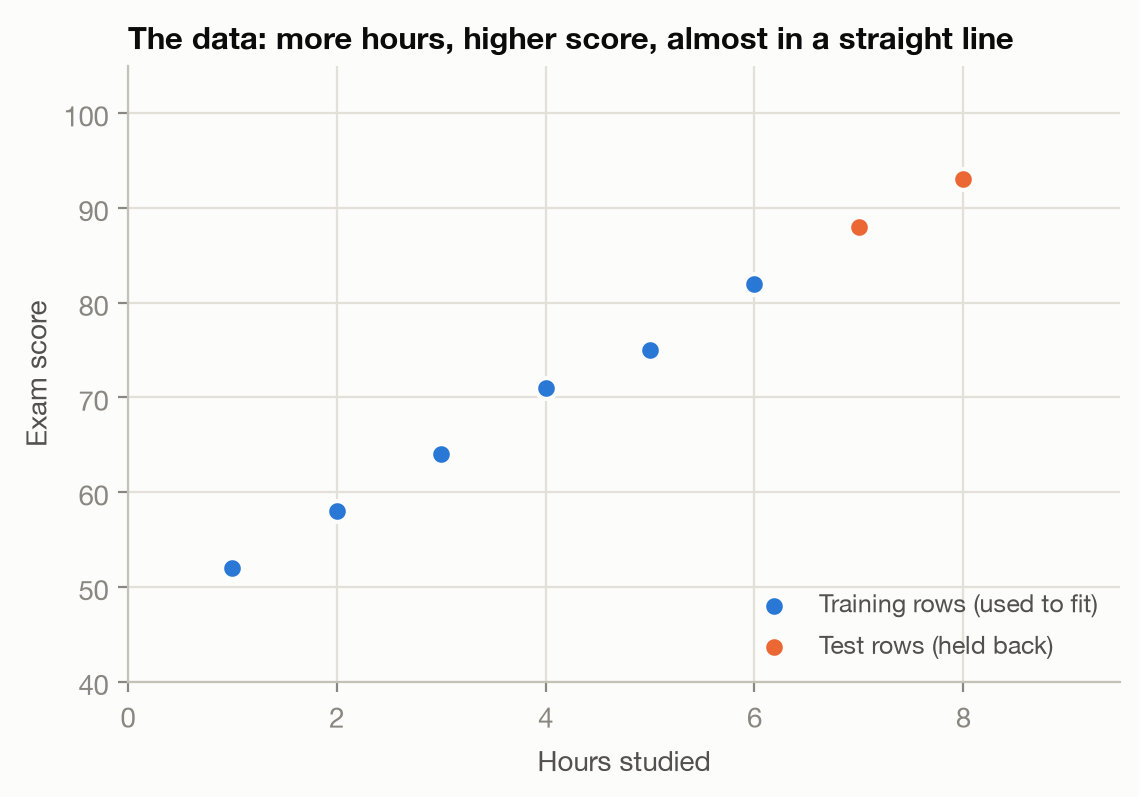

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.scatter(*zip(*train), s=56, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Training rows (used to fit)")
ax.scatter(*zip(*test), s=56, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Test rows (held back)")
ax.set(xlabel="Hours studied", ylabel="Exam score", xlim=(0, 9.5), ylim=(40, 105))
ax.set_title("The data: more hours, higher score, almost in a straight line", loc="left")
ax.legend(loc="lower right")
plt.show()

## Step 2. The model

A model is a formula with numbers in it that nobody has chosen yet. Here the formula is a straight line and the two numbers are `weight` (how many points each extra hour is worth) and `bias` (the score for zero hours). Both start at zero, so the untrained model predicts 0 for everyone.

In [4]:
weight, bias = 0.0, 0.0

def predict(hours):
    return weight * hours + bias

print("Untrained prediction for 5 hours:", predict(5), "(the real student scored 75)")

Untrained prediction for 5 hours: 0.0 (the real student scored 75)


## Step 3. Train

Training repeats one small move thousands of times: measure how wrong the predictions are on the training rows, then nudge `weight` and `bias` a little in the direction that makes the error smaller. `learning_rate` is the size of each nudge.

In [5]:
weight, bias = 0.0, 0.0                       # start from scratch every time this cell runs
learning_rate = 0.01
errors = []                                   # the training error after each step, to plot below

for step in range(5000):
    grad_w = grad_b = mse = 0.0
    for hours, score in train:
        error = predict(hours) - score        # positive means the guess was too high
        grad_w += 2 * error * hours / len(train)
        grad_b += 2 * error / len(train)
        mse += error ** 2 / len(train)
    errors.append(mse)
    weight -= learning_rate * grad_w          # the nudge
    bias -= learning_rate * grad_b

print(f"Learned: score = {weight:.2f} * hours + {bias:.2f}")
print(f"Training error went from {errors[0]:,.0f} to {errors[-1]:.2f}")

Learned: score = 5.94 * hours + 46.20
Training error went from 4,592 to 0.32


The chart below is what training looks like. Each step makes the error a little smaller until there is nothing left to gain.

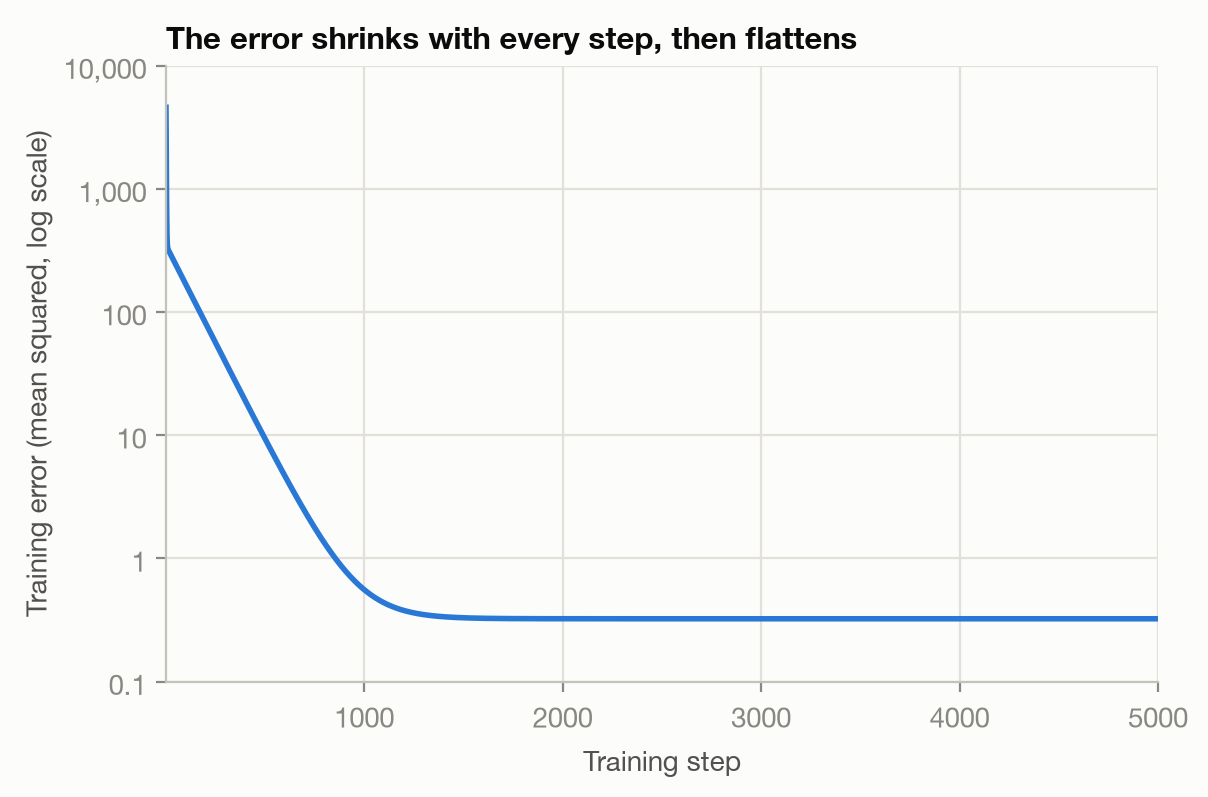

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(range(1, len(errors) + 1), errors, color=BLUE, linewidth=2)
ax.set(xlabel="Training step", ylabel="Training error (mean squared, log scale)", yscale="log", xlim=(1, len(errors)))
ax.set_yticks([0.1, 1, 10, 100, 1000, 10000], ["0.1", "1", "10", "100", "1,000", "10,000"])
ax.tick_params(axis="y", which="minor", left=False)
ax.set_title("The error shrinks with every step, then flattens", loc="left")
plt.show()

## Step 4. Evaluate, then use it

Now the two held-back rows earn their keep. If the model only memorised the training rows, it would do badly here.

In [7]:
for hours, actual in test:
    print(f"{hours} hours -> predicted {predict(hours):.1f}, actual {actual}")
print(f"Prediction for 9 hours (a student we have no data for): {predict(9):.1f}")

7 hours -> predicted 87.8, actual 88
8 hours -> predicted 93.7, actual 93
Prediction for 9 hours (a student we have no data for): 99.7


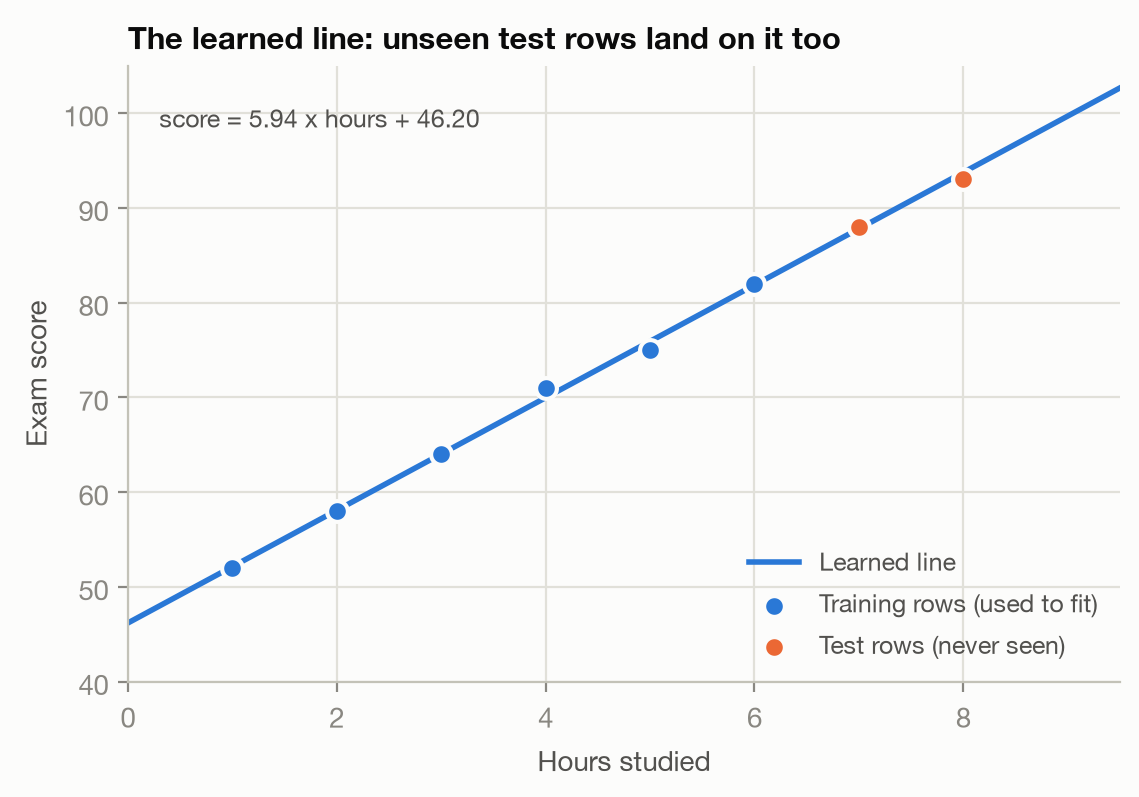

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 4))
xs = [0, 9.5]
ax.plot(xs, [predict(x) for x in xs], color=BLUE, linewidth=2, zorder=2, label="Learned line")
ax.scatter(*zip(*train), s=56, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Training rows (used to fit)")
ax.scatter(*zip(*test), s=56, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Test rows (never seen)")
ax.text(0.3, 101, f"score = {weight:.2f} x hours + {bias:.2f}", color=INK2, fontsize=9, va="top")
ax.set(xlabel="Hours studied", ylabel="Exam score", xlim=(0, 9.5), ylim=(40, 105))
ax.set_title("The learned line: unseen test rows land on it too", loc="left")
ax.legend(loc="lower right")
plt.show()

**Try it.** Go back to the Step 3 cell, change one number, then run that cell and the three cells after it again.

- `learning_rate = 0.001` takes timid steps. After 5000 of them the line is still not in place, and the test predictions get worse.
- `range(5000)` → `range(50)` stops training early. Look at where the error curve ends.
- `learning_rate = 0.05` takes bigger steps and gets to the same line in far fewer of them.
- `learning_rate = 0.07` is too big. Every nudge overshoots, the error grows instead of shrinking, and Python stops with an `OverflowError`. Set it back to `0.01` afterwards.

---
# Part 2. Three classifiers with scikit-learn

Real projects do not write the training loop by hand. scikit-learn is the standard Python machine learning library, and it turns the loop from Part 1 into one line: `model.fit(...)`.

The task is the classic first example: tell three species of iris flower apart using four measurements of each flower. The dataset ships inside scikit-learn, so nothing is downloaded.

## Step 1. The data

In [9]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target       # X = 4 measurements per flower (cm), y = its species as 0, 1 or 2

print(f"{X.shape[0]} flowers, {X.shape[1]} measurements each")
print("Species:", ", ".join(iris.target_names))

# A table is easier to read than raw numbers. Show 8 flowers picked at random.
flowers = pd.DataFrame(X, columns=iris.feature_names)
flowers["species"] = iris.target_names[y]
flowers.sample(8, random_state=0)

150 flowers, 4 measurements each
Species: setosa, versicolor, virginica


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
114,5.8,2.8,5.1,2.4,virginica
62,6.0,2.2,4.0,1.0,versicolor
33,5.5,4.2,1.4,0.2,setosa
107,7.3,2.9,6.3,1.8,virginica
7,5.0,3.4,1.5,0.2,setosa
100,6.3,3.3,6.0,2.5,virginica
40,5.0,3.5,1.3,0.3,setosa
86,6.7,3.1,4.7,1.5,versicolor


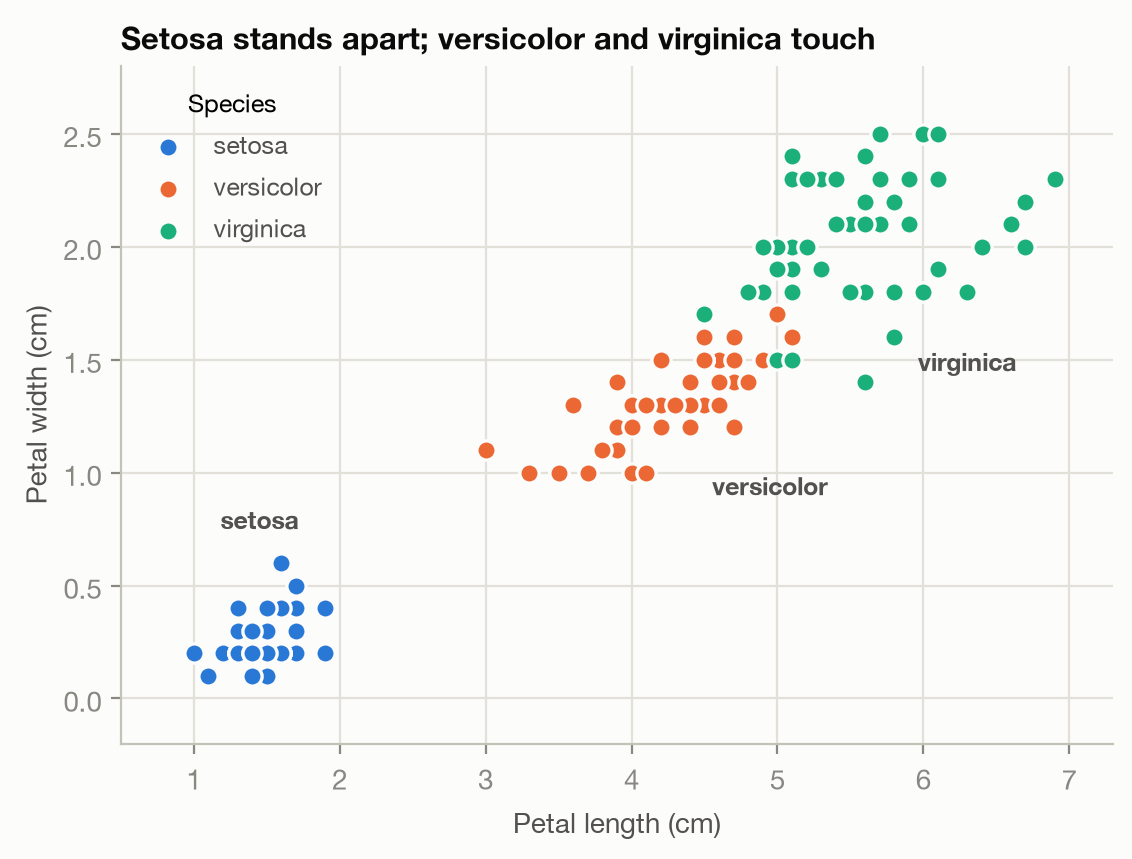

In [10]:
colors = [BLUE, ORANGE, AQUA]                 # setosa, versicolor, virginica
label_at = [(1.45, 0.75), (4.95, 0.9), (6.3, 1.45)]       # an empty spot beside each group for its name

fig, ax = plt.subplots(figsize=(6.4, 4.4))
for k, name in enumerate(iris.target_names):
    petals = X[y == k][:, 2:]                 # columns 2 and 3 are petal length and petal width
    ax.scatter(*petals.T, s=48, color=colors[k], edgecolor=SURFACE, linewidth=1.2, zorder=3, label=name)
    ax.text(*label_at[k], name, color=INK2, fontsize=9, ha="center", fontweight="bold")
ax.set(xlabel="Petal length (cm)", ylabel="Petal width (cm)", xlim=(0.5, 7.3), ylim=(-0.2, 2.8))
ax.set_title("Setosa stands apart; versicolor and virginica touch", loc="left")
ax.legend(loc="upper left", title="Species", title_fontsize=9)
plt.show()

Two of the four measurements are already enough to see the shape of the problem. Setosa is easy. The place where versicolor and virginica meet is where any model will make its mistakes.

## Step 2. Split

Same idea as holding back two students in Part 1, but scikit-learn shuffles first and takes 30%.

In [11]:
from sklearn.model_selection import train_test_split

# random_state=0 makes the shuffle come out the same on every run.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
print(len(X_train), "flowers to train on,", len(X_test), "held back to test on")

105 flowers to train on, 45 held back to test on


## Step 3. Train

Three different kinds of model, trained on the same flowers:

- A **decision tree** learns a series of yes/no questions, such as "is the petal shorter than 2.45 cm?"
- **K nearest neighbors** does not really learn. It looks up the 5 most similar training flowers and takes a vote.
- **Logistic regression** draws straight dividing lines between the species. Despite the name, it is a classifier.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "Decision tree":       DecisionTreeClassifier(random_state=0),
    "K nearest neighbors": KNeighborsClassifier(n_neighbors=5),
    "Logistic regression": LogisticRegression(max_iter=1000),
}
for name, model in models.items():
    model.fit(X_train, y_train)               # fit() is where the learning happens
    print("Trained:", name)

Trained: Decision tree
Trained: K nearest neighbors
Trained: Logistic regression


## Step 4. Evaluate

`score()` is the fraction of the held-back flowers a model labels correctly.

In [13]:
for name, model in models.items():
    print(f"{name}: {model.score(X_test, y_test):.0%} accuracy on unseen flowers")

Decision tree: 98% accuracy on unseen flowers
K nearest neighbors: 98% accuracy on unseen flowers
Logistic regression: 98% accuracy on unseen flowers


The scores alone do not say *which* flowers went wrong, so ask.

In [14]:
for name, model in models.items():
    predicted = model.predict(X_test)
    for i in (predicted != y_test).nonzero()[0]:
        print(f"{name}: test flower {i} {X_test[i].tolist()} is {iris.target_names[y_test[i]]}, the model said {iris.target_names[predicted[i]]}")

Decision tree: test flower 37 [6.0, 2.7, 5.1, 1.6] is versicolor, the model said virginica
K nearest neighbors: test flower 37 [6.0, 2.7, 5.1, 1.6] is versicolor, the model said virginica
Logistic regression: test flower 37 [6.0, 2.7, 5.1, 1.6] is versicolor, the model said virginica


Here all three models miss the same flower. It is a versicolor with petals as long as a virginica's (5.1 cm), so it sits on the wrong side of the border. It shows up again as a ringed dot in Step 6.

## Step 5. Cross-validate

A single split is a small sample. With 45 test flowers, one mistake is worth about 2%, so the three models cannot really be told apart above.

Cross-validation repeats the whole split, train, test cycle 10 times, holding back a different tenth of the flowers each time. The average is a fairer comparison, and the gap between the lowest and highest score shows how much the luck of the split matters.

In [15]:
from sklearn.model_selection import cross_val_score

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=10)          # 10 scores, one per split
    rows.append({"Model": name,
                 "Single split": f"{model.score(X_test, y_test):.0%}",
                 "Average of 10 splits": f"{scores.mean():.1%}",
                 "Lowest": f"{scores.min():.0%}",
                 "Highest": f"{scores.max():.0%}"})
pd.DataFrame(rows).set_index("Model")

,Single split,Average of 10 splits,Lowest,Highest
Model,,,,
Decision tree,98%,96.0%,87%,100%
K nearest neighbors,98%,96.7%,87%,100%
Logistic regression,98%,97.3%,93%,100%


## Step 6. See what each model learned

Each panel below asks a model about every point on the page and tints the page by its answer, which shows where it draws the border between species.

- **Coloured zones:** what the model would answer for a flower at that spot.
- **Dots:** the flowers it learned from, coloured by their true species.
- **Ringed dots:** test flowers it got wrong. Test flowers it got right are not drawn.

The models here are fresh copies trained on petal length and petal width only, so the border can be drawn on a flat page. That is why these percentages can differ slightly from the four-measurement scores above.

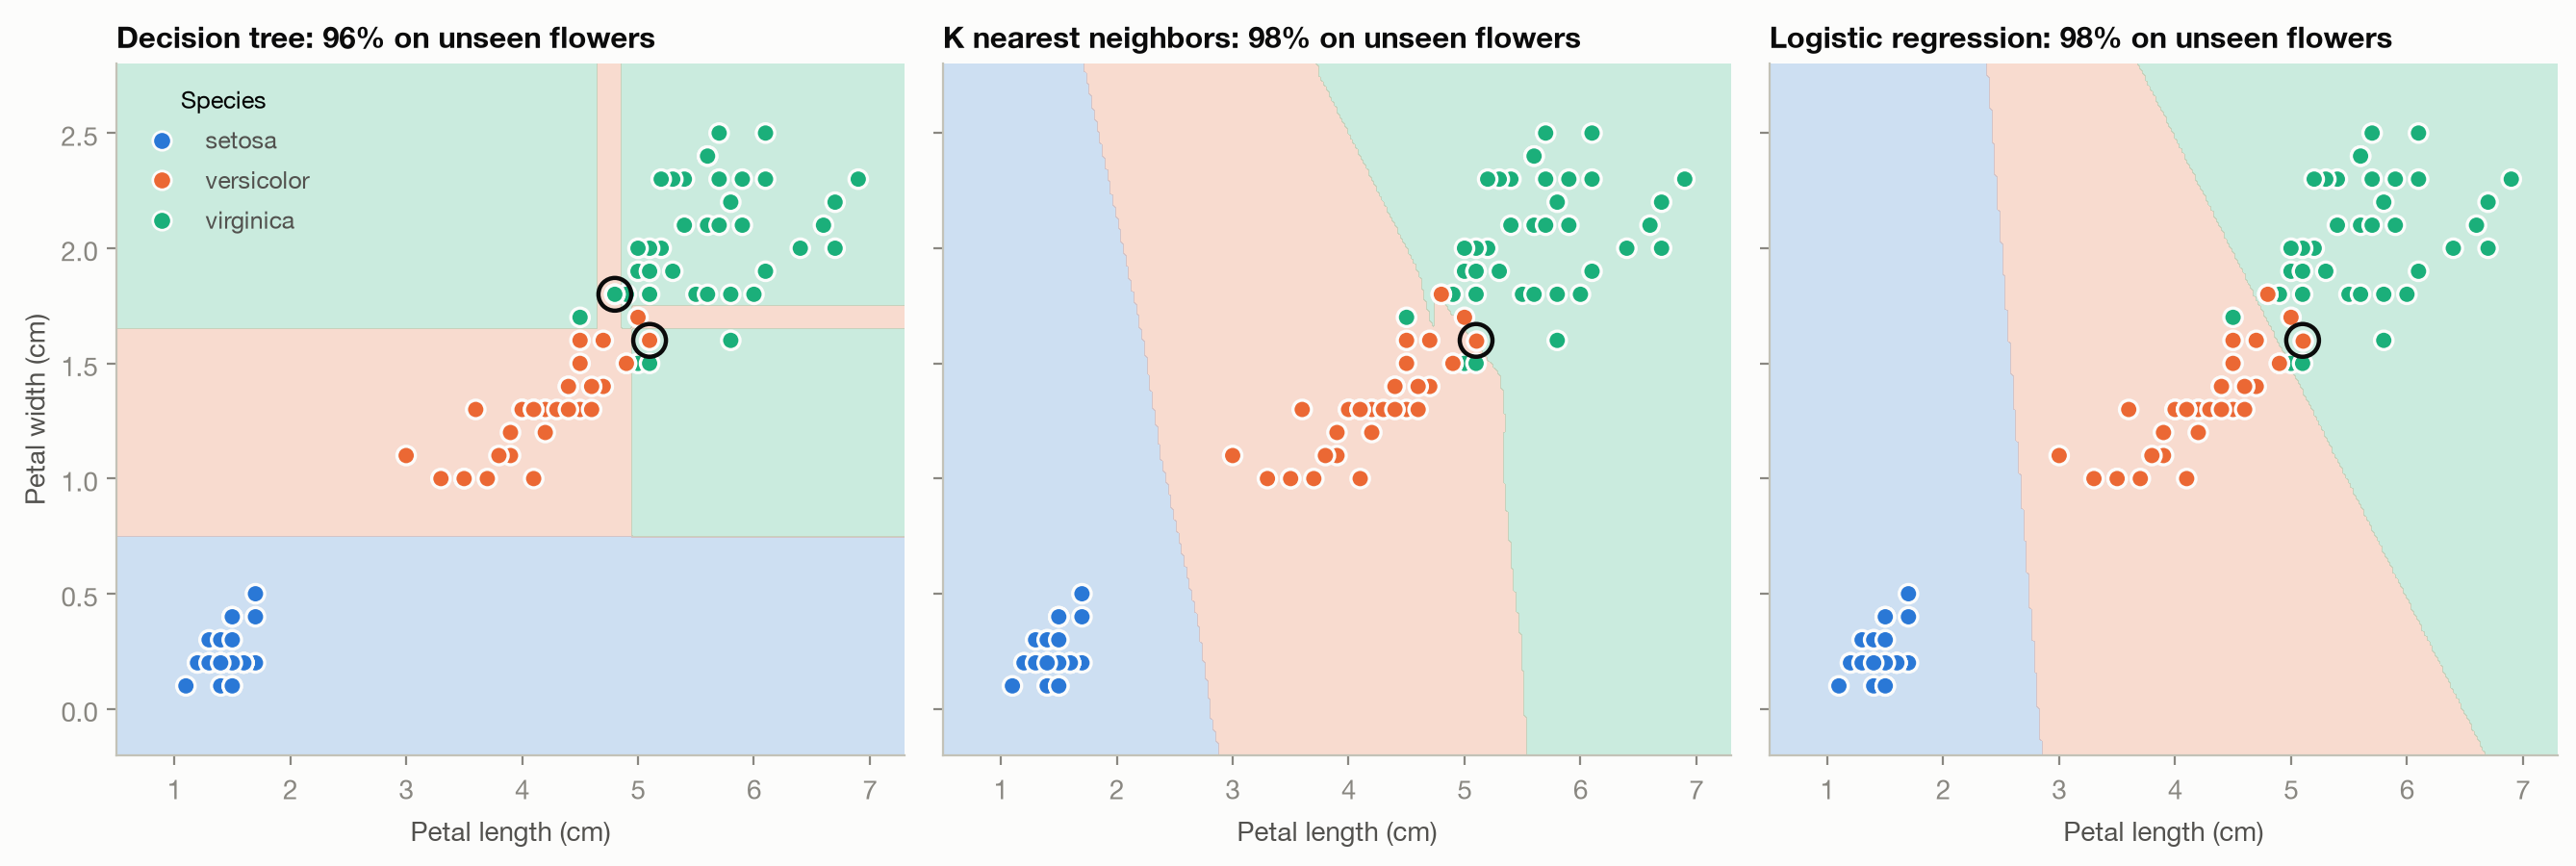

In [16]:
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from sklearn.base import clone

P_train, P_test = X_train[:, 2:], X_test[:, 2:]           # petal length and petal width only
cmap = ListedColormap(colors)
xx, yy = np.meshgrid(np.linspace(0.5, 7.3, 300), np.linspace(-0.2, 2.8, 300))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    flat = clone(model).fit(P_train, y_train)             # a fresh copy, trained on two measurements
    zones = flat.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zones, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.22, zorder=1)
    ax.scatter(*P_train.T, s=48, c=y_train, cmap=cmap, vmin=0, vmax=2, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    wrong = flat.predict(P_test) != y_test
    ax.scatter(*P_test[wrong].T, s=48, c=y_test[wrong], cmap=cmap, vmin=0, vmax=2, edgecolor=SURFACE, linewidth=1.2, zorder=4)
    ax.scatter(*P_test[wrong].T, s=150, facecolor="none", edgecolor=INK, linewidth=1.6, zorder=5)
    ax.set_title(f"{name}: {flat.score(P_test, y_test):.0%} on unseen flowers", loc="left")
    ax.set(xlim=(0.5, 7.3), ylim=(-0.2, 2.8), xlabel="Petal length (cm)")
    ax.grid(False)
axes[0].set_ylabel("Petal width (cm)")
axes[0].legend(handles=[Line2D([], [], marker="o", ls="", markersize=7, markerfacecolor=colors[k], markeredgecolor=SURFACE, label=n)
                        for k, n in enumerate(iris.target_names)], loc="upper left", title="Species", title_fontsize=9)
fig.tight_layout()
plt.show()

The decision tree makes box-shaped cuts, k nearest neighbors traces a wobbly edge around the flowers it remembers, and logistic regression draws straight diagonal lines. All three put the border in nearly the same place, and the mistakes sit right on it.

## Step 7. Use it

A trained model answers questions about flowers it has never seen. Change the four numbers and run the cell again.

In [17]:
new_flower = [[6.5, 3.0, 5.5, 2.0]]      # sepal length, sepal width, petal length, petal width (cm)

for name, model in models.items():
    species = model.predict(new_flower)[0]
    print(f"{name} says: {iris.target_names[species]}")

Decision tree says: virginica
K nearest neighbors says: virginica
Logistic regression says: virginica


**Try it.** K nearest neighbors has one setting, `k`: how many neighbours get a vote. Change `k` below to 1, 15 or 51 and run the cell each time.

- With `k = 1` the model scores 100% on the flowers it trained on, because every flower is its own nearest neighbour. That is memorising, and it does not carry over to unseen flowers.
- A very large `k` lets flowers from the wrong species join the vote, and accuracy drops.

In [18]:
k = 5      # try 1, 15 or 51, then run this cell again

knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
print(f"k = {k}")
print(f"  accuracy on the flowers it trained on: {knn.score(X_train, y_train):.0%}")
print(f"  accuracy on unseen test flowers:       {knn.score(X_test, y_test):.0%}")
print(f"  average over 10 splits:                {cross_val_score(knn, X, y, cv=10).mean():.1%}")

k = 5
  accuracy on the flowers it trained on: 97%
  accuracy on unseen test flowers:       98%
  average over 10 splits:                96.7%


---
# Part 3. Save the model and load it back

Once you have picked a model, you train it on **all** the data (the held-back test set has done its job) and save the fitted model to a file. Any other Python program can then load the file and ask it questions without training anything.

This is what `save_model.py` does. The notebook writes to its own file, `notebook_model.joblib`, so it does not touch the `iris_model.joblib` that `client.py` uses.

In [19]:
import joblib
import sklearn

final_model = LogisticRegression(max_iter=1000).fit(X, y)      # the chosen model, trained on every flower

# Save the model together with everything a client needs to make sense of its answers.
package = {
    "model": final_model,
    "species": list(iris.target_names),                   # 0, 1, 2 -> names
    "inputs": ["sepal length", "sepal width", "petal length", "petal width"],   # in cm, in this order
    "sklearn_version": sklearn.__version__,               # the client should match this
}
joblib.dump(package, "notebook_model.joblib")
print(f"Saved notebook_model.joblib (trained on {len(X)} flowers with scikit-learn {sklearn.__version__})")

Saved notebook_model.joblib (trained on 150 flowers with scikit-learn 1.9.1)


The next cell is everything a client program needs. It does not train and it does not load the dataset. This is what `client.py` does.

In [20]:
loaded = joblib.load("notebook_model.joblib")

measurements = [6.5, 3.0, 5.5, 2.0]
answer = loaded["model"].predict([measurements])[0]
confidence = loaded["model"].predict_proba([measurements])[0][answer]
print(f"{measurements} cm -> {loaded['species'][answer]} ({confidence:.0%} sure)")

[6.5, 3.0, 5.5, 2.0] cm -> virginica (93% sure)


Two things to know about `.joblib` files. They only work reliably with the same scikit-learn version that saved them, which is why the version is stored alongside the model. And they are Python pickles, so only load files you made or trust.

---
# Where to go next

- Add a fourth model to the `models` dictionary in Part 2, Step 3, for example `RandomForestClassifier` from `sklearn.ensemble`, then run the cells below it again.
- Load your own CSV with `pd.read_csv("your_file.csv")` and feed its columns to the same code.
- The plain scripts in this folder do the same work without a notebook. `README.md` lists them and how to run each one.